In [ ]:
# ============================================================
# EXPERIMENT: SUPPORT VECTOR MACHINE (SVM)
# ============================================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


# ============================================================
# 2. Load Dataset
# ============================================================

df = pd.read_csv("Social_Network_Ads.csv")

print("First 5 rows:")
print(df.head())


# ============================================================
# 3. Select Features and Target
# ============================================================

X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


# ============================================================
# 4. Split Dataset into Training and Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 5. Feature Scaling
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nFeature scaling completed.")


# ============================================================
# 6. LINEAR KERNEL
# ============================================================

linear_model = SVC(kernel='linear')

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_accuracy = accuracy_score(y_test, linear_pred)

print("\n--------------------------------")
print("LINEAR KERNEL")
print("--------------------------------")
print("Accuracy:", linear_accuracy)


# ============================================================
# 7. POLYNOMIAL KERNEL
# ============================================================

poly_model = SVC(kernel='poly')

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

poly_accuracy = accuracy_score(y_test, poly_pred)

print("\n--------------------------------")
print("POLYNOMIAL KERNEL")
print("--------------------------------")
print("Accuracy:", poly_accuracy)


# ============================================================
# 8. RBF KERNEL
# ============================================================

rbf_model = SVC(kernel='rbf')

rbf_model.fit(X_train, y_train)

rbf_pred = rbf_model.predict(X_test)

rbf_accuracy = accuracy_score(y_test, rbf_pred)

print("\n--------------------------------")
print("RBF KERNEL")
print("--------------------------------")
print("Accuracy:", rbf_accuracy)


# ============================================================
# 9. Compare Accuracy
# ============================================================

print("\n================================")
print("ACCURACY COMPARISON")
print("================================")

print("Linear Kernel     :", linear_accuracy)
print("Polynomial Kernel :", poly_accuracy)
print("RBF Kernel        :", rbf_accuracy)


# ============================================================
# 10. Confusion Matrix
# ============================================================

print("\n================================")
print("CONFUSION MATRIX - RBF")
print("================================")

print(confusion_matrix(y_test, rbf_pred))


# ============================================================
# 11. GRID SEARCH FOR C AND GAMMA
# ============================================================

parameters = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

grid = GridSearchCV(
    SVC(kernel='rbf'),
    parameters,
    cv=5
)

grid.fit(X_train, y_train)


# ============================================================
# 12. Best Parameters
# ============================================================

print("\n================================")
print("GRID SEARCH RESULTS")
print("================================")

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)


# ============================================================
# 13. Final Model using Best Parameters
# ============================================================

best_model = grid.best_estimator_

best_pred = best_model.predict(X_test)

best_accuracy = accuracy_score(y_test, best_pred)

print("\nFinal Test Accuracy:", best_accuracy)


# ============================================================
# 14. Number of Support Vectors
# ============================================================

print("\nNumber of Support Vectors:",
      len(best_model.support_vectors_))


# ============================================
# SIMPLE SVM GRAPH
# ============================================

def svm_graph(model, X, y, title):

    # Create simple grid
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1
    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.05),
        np.arange(y_min, y_max, 0.05)
    )

    # Predict grid points
    points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(points)
    Z = Z.reshape(xx.shape)

    # Draw classes
    plt.contourf(xx, yy, Z, alpha=0.2)

    # Class 0
    plt.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        marker='o',
        label='Class 0'
    )

    # Class 1
    plt.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        marker='^',
        label='Class 1'
    )

    # Support Vectors
    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100,
        facecolors='none',
        edgecolors='red',
        linewidths=2,
        label='Support Vectors'
    )

    plt.xlabel("Age")
    plt.ylabel("Estimated Salary")
    plt.title(title)
    plt.legend()
    plt.show()


    svm_graph(
    linear_model,
    X_train,
    y_train,
    "SVM - Linear Kernel"
)
    svm_graph(
    poly_model,
    X_train,
    y_train,
    "SVM - Polynomial Kernel"
)
    svm_graph(
    rbf_model,
    X_train,
    y_train,
    "SVM - RBF Kernel"
)

First 5 rows:
   Age  EstimatedSalary  Purchased
0   19            19000          0
1   35            20000          0
2   26            43000          0
3   27            57000          0
4   19            76000          0

Features:
   Age  EstimatedSalary
0   19            19000
1   35            20000
2   26            43000
3   27            57000
4   19            76000

Target:
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

Training data: (320, 2)
Testing data: (80, 2)

Feature scaling completed.

--------------------------------
LINEAR KERNEL
--------------------------------
Accuracy: 0.8625

--------------------------------
POLYNOMIAL KERNEL
--------------------------------
Accuracy: 0.875

--------------------------------
RBF KERNEL
--------------------------------
Accuracy: 0.925

ACCURACY COMPARISON
Linear Kernel     : 0.8625
Polynomial Kernel : 0.875
RBF Kernel        : 0.925

CONFUSION MATRIX - RBF
[[47  5]
 [ 1 27]]

GRID SEARCH RESULTS
Best Parameters

   Age  EstimatedSalary  Purchased
0   19            19000          0
1   35            20000          0
2   26            43000          0
3   27            57000          0
4   19            76000          0
(400, 3)
Linear Kernel Accuracy: 0.8625
Polynomial Kernel Accuracy: 0.875
RBF Kernel Accuracy: 0.925

Confusion Matrix - RBF
[[47  5]
 [ 1 27]]

Best Parameters:
{'C': 0.1, 'gamma': 1}
Best RBF Accuracy: 0.925

Number of Support Vectors:
175


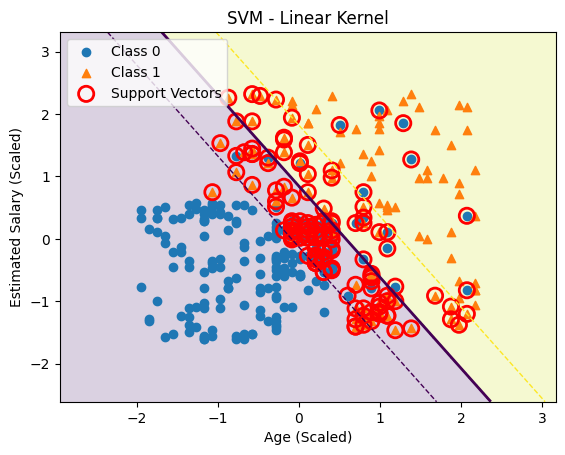

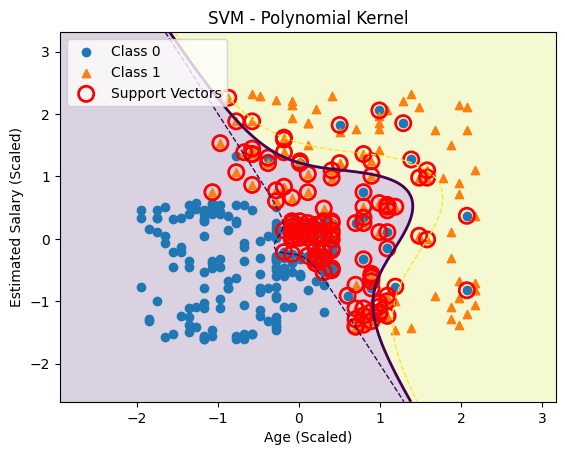

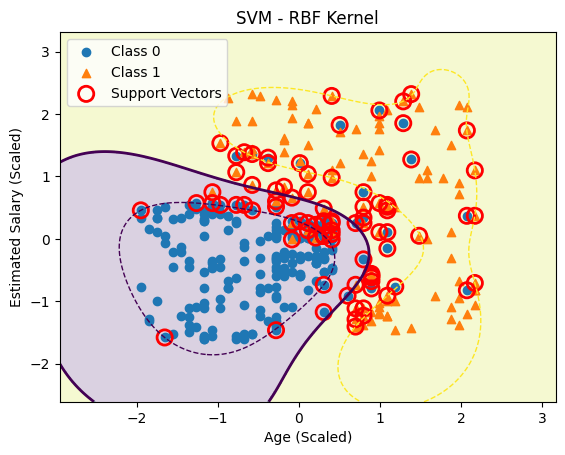

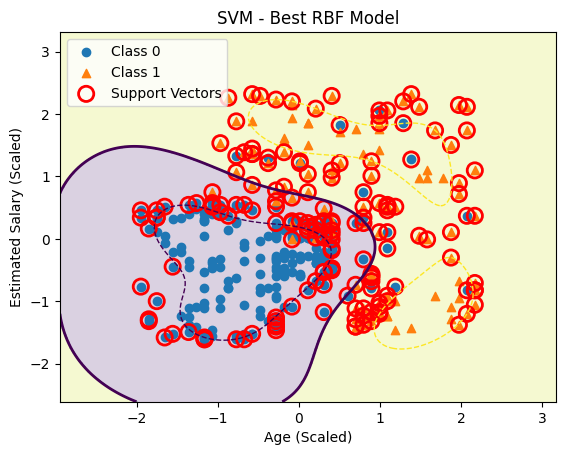

In [ ]:
# ============================================
# SVM CLASSIFICATION - SOCIAL NETWORK ADS
# ============================================

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


# 2. Load dataset
df = pd.read_csv("Social_Network_Ads.csv")

print(df.head())
print(df.shape)


# 3. Select features and target
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']


# 4. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


# 5. Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================
# 6. LINEAR KERNEL
# ============================================

linear_model = SVC(kernel='linear')
linear_model.fit(X_train_scaled, y_train)

linear_pred = linear_model.predict(X_test_scaled)

linear_accuracy = accuracy_score(y_test, linear_pred)

print("Linear Kernel Accuracy:",
      linear_accuracy)


# ============================================
# 7. POLYNOMIAL KERNEL
# ============================================

poly_model = SVC(kernel='poly')

poly_model.fit(X_train_scaled, y_train)

poly_pred = poly_model.predict(X_test_scaled)

poly_accuracy = accuracy_score(y_test, poly_pred)

print("Polynomial Kernel Accuracy:",
      poly_accuracy)


# ============================================
# 8. RBF KERNEL
# ============================================

rbf_model = SVC(kernel='rbf')

rbf_model.fit(X_train_scaled, y_train)

rbf_pred = rbf_model.predict(X_test_scaled)

rbf_accuracy = accuracy_score(y_test, rbf_pred)

print("RBF Kernel Accuracy:",
      rbf_accuracy)


# ============================================
# 9. CONFUSION MATRIX
# ============================================

print("\nConfusion Matrix - RBF")

cm = confusion_matrix(y_test, rbf_pred)

print(cm)


# ============================================
# 10. GRID SEARCH FOR BEST C AND GAMMA
# ============================================

parameters = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

grid = GridSearchCV(
    SVC(kernel='rbf'),
    parameters,
    cv=5
)

grid.fit(X_train_scaled, y_train)


print("\nBest Parameters:")
print(grid.best_params_)


# Best model
best_model = grid.best_estimator_

best_pred = best_model.predict(X_test_scaled)

best_accuracy = accuracy_score(
    y_test,
    best_pred
)

print("Best RBF Accuracy:",
      best_accuracy)


# ============================================
# 11. SUPPORT VECTORS
# ============================================

print("\nNumber of Support Vectors:")
print(len(best_model.support_))


# ============================================
# 12. GRAPH FUNCTION
# ============================================

def svm_graph(model, X, y, title):

    # Create grid
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1

    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Predict every point in grid
    points = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(points)
    Z = Z.reshape(xx.shape)

    # Show classification regions
    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.2
    )

    # Get decision function
    decision = model.decision_function(points)
    decision = decision.reshape(xx.shape)

    # Decision boundary
    plt.contour(
        xx,
        yy,
        decision,
        levels=[0],
        linewidths=2
    )

    # Margins
    plt.contour(
        xx,
        yy,
        decision,
        levels=[-1, 1],
        linestyles='--',
        linewidths=1
    )

    # Class 0
    plt.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        marker='o',
        label='Class 0'
    )

    # Class 1
    plt.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        marker='^',
        label='Class 1'
    )

    # Support vectors
    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=120,
        facecolors='none',
        edgecolors='red',
        linewidths=2,
        label='Support Vectors'
    )

    plt.xlabel("Age (Scaled)")
    plt.ylabel("Estimated Salary (Scaled)")
    plt.title(title)

    plt.legend()
    plt.show()


# ============================================
# 13. DISPLAY GRAPHS
# ============================================

svm_graph(
    linear_model,
    X_train_scaled,
    y_train.to_numpy(),
    "SVM - Linear Kernel"
)

svm_graph(
    poly_model,
    X_train_scaled,
    y_train.to_numpy(),
    "SVM - Polynomial Kernel"
)

svm_graph(
    rbf_model,
    X_train_scaled,
    y_train.to_numpy(),
    "SVM - RBF Kernel"
)

svm_graph(
    best_model,
    X_train_scaled,
    y_train.to_numpy(),
    "SVM - Best RBF Model"
)